In [34]:
def cylinder_panels(n,r=1):
  theta=np.linspace(2*np.pi,0,n+1)
  x=r*np.cos(theta)
  y=r*np.sin(theta)
  return(x,y)



In [35]:
def naca4_panels(code, n, spacing="cosine"):
    
    m = int(code[0]) / 100        # max camber
    p = int(code[1]) / 10         # location of max camber
    t = int(code[2:]) / 100       # thickness

    half = n // 2
    if spacing == "cosine":
        beta = np.linspace(0, np.pi, half + 1)
        x = 0.5 * (1 - np.cos(beta))
    else:                          # uniform
        x = np.linspace(0, 1, half + 1)

    # thickness distribution (-0.1036 makes the trailing edge closed)
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2
              + 0.2843*x**3 - 0.1036*x**4)

    # camber line and its slope
    if m == 0:
        yc = np.zeros_like(x)
        dyc = np.zeros_like(x)
    else:
        yc = np.where(x < p,
                      m/p**2 * (2*p*x - x**2),
                      m/(1-p)**2 * ((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p,
                       2*m/p**2 * (p - x),
                       2*m/(1-p)**2 * (p - x))
    th = np.arctan(dyc)

    xu = x - yt*np.sin(th);  yu = yc + yt*np.cos(th)
    xl = x + yt*np.sin(th);  yl = yc - yt*np.cos(th)

    # clockwise: lower surface from TE to LE, then upper surface LE to TE
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    return xb, yb

In [40]:
def panel_geometry(xb, yb):
    dx = np.diff(xb)
    dy = np.diff(yb)
    xc = 0.5 * (xb[:-1] + xb[1:])      # control points (midpoints)
    yc = 0.5 * (yb[:-1] + yb[1:])
    S = np.hypot(dx, dy)                # panel lengths
    sin_t = dy / S                      # panel angle (relative to x-axis)
    cos_t = dx / S
    return xc, yc, S, sin_t, cos_t

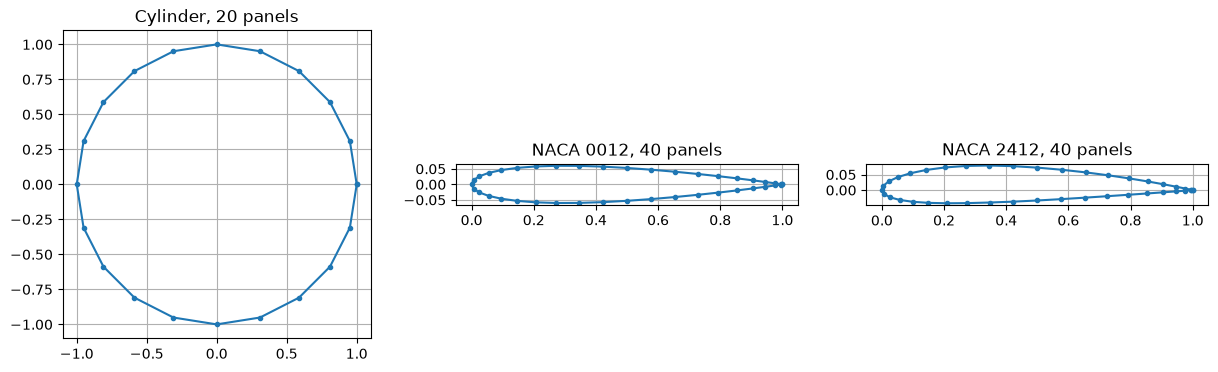

In [41]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, 20 panels": cylinder_panels(20),
        "NACA 0012, 40 panels": naca4_panels("0012", 40),
        "NACA 2412, 40 panels": naca4_panels("2412", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3)
    a.set_aspect("equal"); a.set_title(name); a.grid(True)
plt.show()

## Defining Vortex panel method

In [42]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    
    alpha = np.radians(alpha_deg)
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

                                                # influence-coefficient matrix
    A = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                continue                       # self-influence on normal velocity = 0
            dx = xc[i] - xb[j]
            dy = yc[i] - yb[j]
            xi  =  dx*cos_t[j] + dy*sin_t[j]   # local coordinates of point i
            eta = -dx*sin_t[j] + dy*cos_t[j]   # in panel j's frame
            th1 = np.arctan2(eta, xi)
            th2 = np.arctan2(eta, xi - S[j])
            r1 = np.hypot(xi, eta)
            r2 = np.hypot(xi - S[j], eta)
            A[i, j] = ((th2 - th1)*np.sin(theta[j] - theta[i])
                       + np.log(r2/r1)*np.cos(theta[i] - theta[j])) / (2*np.pi)

   
    b = V_inf*np.sin(theta - alpha)

                                              # Kutta condition replaces the last equation
    A[-1, :] = 0.0
    A[-1, 0] = 1.0
    A[-1, -1] = 1.0
    b[-1] = 0.0

   
    gamma = np.linalg.solve(A, b)

    Cp = 1 - (gamma/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(gamma*S)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "xc": xc, "yc": yc, "S": S}

N =   11   max |Cp error| = 1.0871   Cl = -2.49e-15
N =   21   max |Cp error| = 0.5500   Cl = -2.07e-14
N =   41   max |Cp error| = 0.2763   Cl = -2.32e-14
N =   81   max |Cp error| = 0.1384   Cl = 2.67e-14
N =  161   max |Cp error| = 0.0693   Cl = 3.91e-14


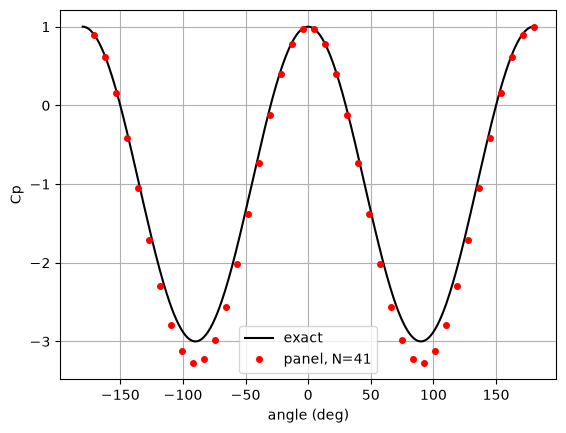

NACA0012, 5 deg, Cl = 0.6047648353301915


In [43]:
# Cylinder: exact solution is Cp = 1 - 4 sin^2(phi), and Cl = 0
# Odd numbers are used to avoid symmetry-related numerical issues and to keep stagnation points away from panel boundaries, resulting in more stable and accurate vortex-panel solutions.
for n in [11, 21, 41, 81, 161]:                                      
    xb, yb = cylinder_panels(n)
    r = vortex_panel_method_0(xb, yb, 0.0)
    phi = np.arctan2(r["yc"], r["xc"])
    err = np.max(np.abs(r["Cp"] - (1 - 4*np.sin(phi)**2)))
    print(f"N = {n:4d}   max |Cp error| = {err:.4f}   Cl = {r['Cl']:.2e}")

# Compare with the exact curve for N = 41
xb, yb = cylinder_panels(41)
r = vortex_panel_method_0(xb, yb, 0.0)
phi = np.arctan2(r["yc"], r["xc"])
pe = np.linspace(-np.pi, np.pi, 400)
plt.plot(np.degrees(pe), 1 - 4*np.sin(pe)**2, "k", label="exact")
plt.plot(np.degrees(phi), r["Cp"], "ro", ms=4, label="panel, N=41")
plt.xlabel("angle (deg)"); plt.ylabel("Cp"); plt.legend(); plt.grid(True)
plt.show()

# Quick airfoil sanity check: NACA 0012 at 5 deg, expect Cl a bit above 0.55
xb, yb = naca4_panels("0012", 160)
print("NACA0012, 5 deg, Cl =", vortex_panel_method_0(xb, yb, 5.0)["Cl"])